# Praktikum: Klasifikasi Citra Emosi Wajah Menggunakan CNN dengan Dashboard Streamlit
Dataset: [Facial Emotion Recognition Dataset (Kaggle)](https://www.kaggle.com/datasets/fahadullaha/facial-emotion-recognition-dataset/data)

Urutan notebook mengikuti Langkah 1–7 pada soal praktikum. Langkah 7 (dashboard) ada di file `app.py`, dijalankan dengan `streamlit run app.py` setelah notebook ini selesai.

In [1]:
%pip uninstall -y opencv-python
%pip install "opencv-python<5"

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


   ---------------------------------------- 0.0/41.2 MB ? eta -:--:--
    --------------------------------------- 0.8/41.2 MB 3.3 MB/s eta 0:00:13
   - -------------------------------------- 1.3/41.2 MB 2.9 MB/s eta 0:00:14
   - -------------------------------------- 1.6/41.2 MB 2.5 MB/s eta 0:00:16
   - -------------------------------------- 1.8/41.2 MB 2.0 MB/s eta 0:00:20
   -- ------------------------------------- 2.4/41.2 MB 2.1 MB/s eta 0:00:19
   -- ------------------------------------- 2.9/41.2 MB 2.3 MB/s eta 0:00:17
   --- ------------------------------------ 3.9/41.2 MB 2.6 MB/s eta 0:00:15
   ---- ----------------------------------- 4.7/41.2 MB 2.8 MB/s eta 0:00:13
   ----- ---------------------------------- 5.5/41.2 MB 3.0 MB/s eta 0:00:13
   ------ --------------------------------- 6.3/41.2 MB 3.1 MB/s eta 0:00:12
   ------ --------------------------------- 7.1/41.2 MB 3.0 MB/s eta 0:00:12
   ------- -------------------------------- 7.6/41.2 MB 3.0 MB/s eta 0:00:12
   ---

In [4]:
%pip install tensorflow numpy matplotlib scikit-learn streamlit pillow pandas certifi

Note: you may need to restart the kernel to use updated packages.


## Import library

In [5]:
import os
import json
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# (opsional) perbaikan SSL jika download dataset/bobot gagal di Windows
try:
    import ssl, certifi
    os.environ['SSL_CERT_FILE'] = certifi.where()
    os.environ['REQUESTS_CA_BUNDLE'] = certifi.where()
    ssl._create_default_https_context = lambda *a, **k: ssl.create_default_context(cafile=certifi.where())
except Exception:
    pass

## Langkah 1 — Pengambilan dan Pemahaman Dataset
Isi `BASE_DIR` dengan lokasi folder dataset yang sudah ada di komputer Anda (sudah di-extract).

In [6]:
# ====== KONFIGURASI ======
BASE_DIR = 'D:/emosiiii/processed_data'   # <-- UBAH sesuai lokasi dataset Anda
IMG_SIZE = (48, 48)        # Langkah 3: ukuran seragam 48x48 piksel
BATCH = 64                 # Langkah 4: batch size
EPOCHS = 40                # Langkah 4: jumlah epoch maksimum (ada EarlyStopping)
LEARNING_RATE = 1e-3       # Langkah 4: learning rate
TEST_SIZE = 0.2            # Langkah 3: 80% training, 20% validation/test
SAMPLE_N = 3000            # jumlah gambar yang diperiksa untuk analisis kualitas (EDA)
SEED = 42
OUT_DIR = 'output'
os.makedirs(OUT_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)

if not os.path.isdir(BASE_DIR):
    raise FileNotFoundError(f'Folder dataset tidak ditemukan: {BASE_DIR}. Periksa kembali BASE_DIR.')
print(f'Dataset: {BASE_DIR}')

Dataset: D:/emosiiii/processed_data


In [7]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp')

def collect_images(root):
    # Telusuri semua subfolder. Nama folder yang langsung berisi gambar = nama kelas.
    # Struktur train/test (atau train/val/test) otomatis tertangani dan digabung dulu,
    # karena soal meminta pembagian ulang 80% / 20%.
    paths, labels, splits = [], [], []
    for dirpath, _, files in os.walk(root):
        imgs = [f for f in files if f.lower().endswith(IMG_EXT)]
        if not imgs:
            continue
        rel = os.path.relpath(dirpath, root).split(os.sep)
        label = rel[-1].lower()
        split = rel[-2] if len(rel) >= 2 else '(root)'
        for f in imgs:
            paths.append(os.path.join(dirpath, f))
            labels.append(label)
            splits.append(split)
    return paths, labels, splits

paths_all, labels_all, splits_all = collect_images(BASE_DIR)

class_names = sorted(set(labels_all))
NUM_CLASSES = len(class_names)
if NUM_CLASSES < 2:
    raise RuntimeError(
        f'Hanya ditemukan {NUM_CLASSES} kelas: {class_names}. Pastikan BASE_DIR berisi folder per emosi '
        '(mis. .../train/angry, .../train/happy, dst).'
    )

class_to_idx = {c: i for i, c in enumerate(class_names)}
paths_all = np.array(paths_all)
y_all = np.array([class_to_idx[l] for l in labels_all], dtype=np.int32)

# Struktur folder asli dataset
print('Struktur folder dataset (jumlah gambar per kelas x folder):\n')
print(pd.crosstab(pd.Series(labels_all, name='kelas'), pd.Series(splits_all, name='folder')))

print(f'\nJumlah kelas emosi : {NUM_CLASSES}')
print(f'Nama kelas         : {class_names}')
print(f'Total gambar       : {len(paths_all)}')

with open(os.path.join(OUT_DIR, 'class_names.json'), 'w') as f:
    json.dump(class_names, f)

Struktur folder dataset (jumlah gambar per kelas x folder):

folder    (root)
kelas           
angry       5920
disgust     5920
fear        5920
happy      11398
neutral     8166
sad         6535
surprise    5920

Jumlah kelas emosi : 7
Nama kelas         : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Total gambar       : 49779


## Langkah 2 — Eksplorasi Data (EDA)

          jumlah  persen (%)
angry       5920       11.89
disgust     5920       11.89
fear        5920       11.89
happy      11398       22.90
neutral     8166       16.40
sad         6535       13.13
surprise    5920       11.89

Kelas terbanyak : happy (11398)
Kelas tersedikit: angry (5920)
Rasio imbalance (terbanyak / tersedikit): 1.93x
=> Terdapat ketidakseimbangan data antar kelas (class imbalance).


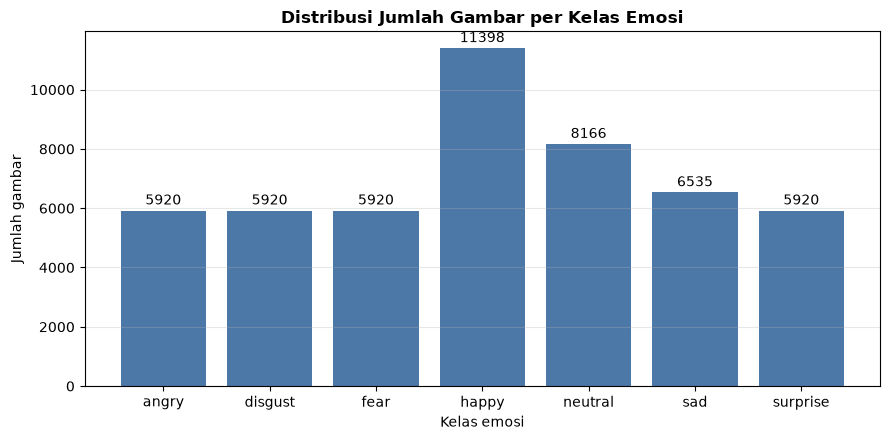

In [8]:
# 2a. Distribusi jumlah gambar tiap kelas + deteksi class imbalance
counts = {c: int((y_all == i).sum()) for i, c in enumerate(class_names)}
df_counts = pd.DataFrame({'jumlah': counts})
df_counts['persen (%)'] = (df_counts['jumlah'] / df_counts['jumlah'].sum() * 100).round(2)
print(df_counts)

max_c, min_c = max(counts, key=counts.get), min(counts, key=counts.get)
imbalance_ratio = counts[max_c] / counts[min_c]
print(f'\nKelas terbanyak : {max_c} ({counts[max_c]})')
print(f'Kelas tersedikit: {min_c} ({counts[min_c]})')
print(f'Rasio imbalance (terbanyak / tersedikit): {imbalance_ratio:.2f}x')
if imbalance_ratio > 1.5:
    print('=> Terdapat ketidakseimbangan data antar kelas (class imbalance).')
else:
    print('=> Distribusi kelas relatif seimbang.')

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(list(counts.keys()), list(counts.values()), color='#4C78A8')
ax.bar_label(bars, padding=2)
ax.set_title('Distribusi Jumlah Gambar per Kelas Emosi', fontweight='bold')
ax.set_xlabel('Kelas emosi'); ax.set_ylabel('Jumlah gambar')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '1_class_distribution.png'), dpi=120, bbox_inches='tight')
plt.show()

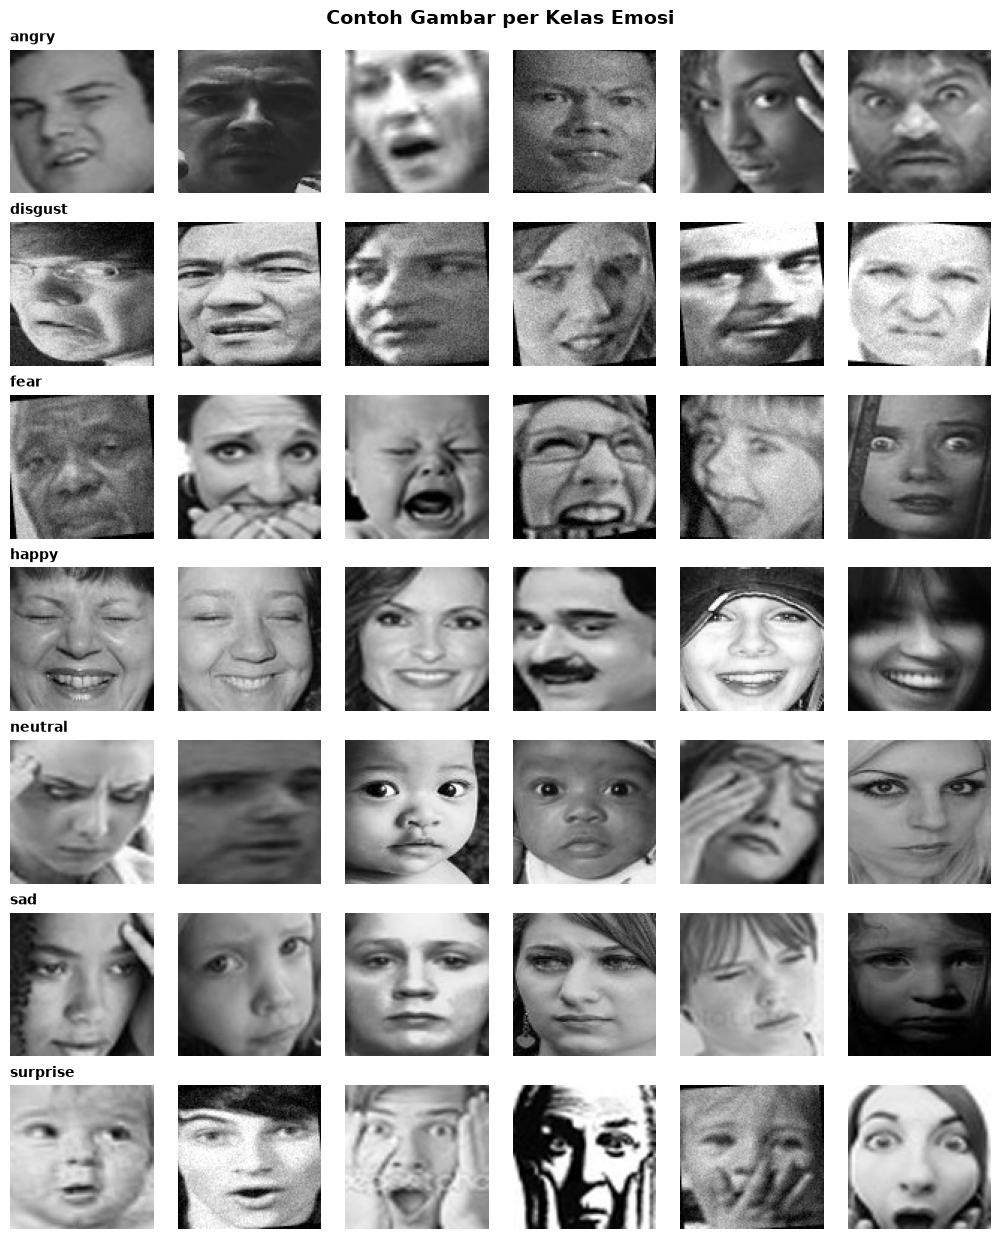

In [9]:
# 2b. Contoh gambar dari setiap kelas
n_per = 6
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(NUM_CLASSES, n_per, figsize=(n_per * 1.7, NUM_CLASSES * 1.8))
for r, cname in enumerate(class_names):
    idxs = np.where(y_all == r)[0]
    pick = rng.choice(idxs, size=min(n_per, len(idxs)), replace=False)
    for c in range(n_per):
        ax = axes[r, c]
        ax.axis('off')
        if c < len(pick):
            ax.imshow(Image.open(paths_all[pick[c]]).convert('L'), cmap='gray', vmin=0, vmax=255)
        if c == 0:
            ax.set_title(cname, loc='left', fontsize=10, fontweight='bold')
plt.suptitle('Contoh Gambar per Kelas Emosi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '2_sample_per_class.png'), dpi=120, bbox_inches='tight')
plt.show()

Gambar diperiksa : 3000 (sampel acak dari 49779)
Ukuran (lebar, tinggi): {(96, 96): 3000}
Mode warna            : {'RGB': 3000}   (L = grayscale, RGB = berwarna)
Format file           : {'JPEG': 3000}
Gambar rusak/tidak terbaca: 0
Rata-rata kecerahan   : 130.5 (skala 0-255), std 33.7
Rata-rata kontras     : 49.2 (std piksel per gambar)
Terlalu gelap (kecerahan < 40)  : 10 gambar
Terlalu terang (kecerahan > 215): 5 gambar
Kontras rendah (std < 20)       : 26 gambar


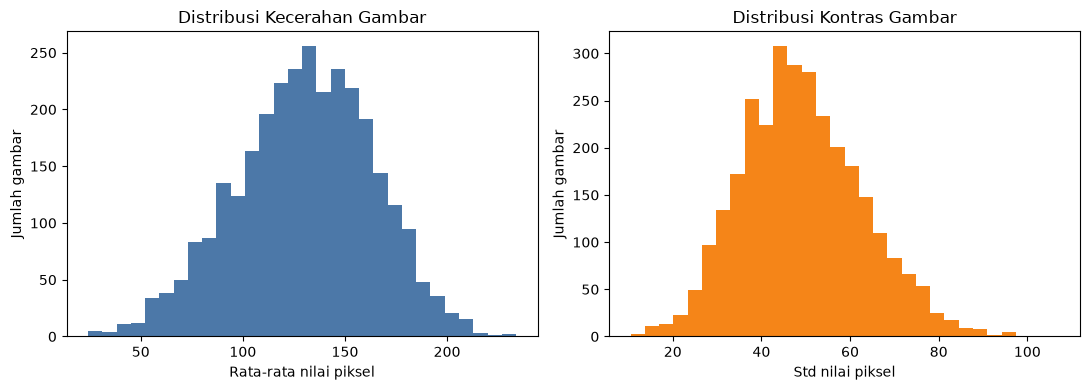

In [10]:
# 2c. Ukuran gambar, format warna (grayscale/RGB), dan kualitas gambar (pada sampel acak)
sample_idx = rng.choice(len(paths_all), size=min(SAMPLE_N, len(paths_all)), replace=False)
sizes, modes, formats = Counter(), Counter(), Counter()
brightness, contrast = [], []
corrupt = 0

for i in sample_idx:
    try:
        with Image.open(paths_all[i]) as im:
            sizes[im.size] += 1
            modes[im.mode] += 1
            formats[im.format] += 1
            arr = np.asarray(im.convert('L'), dtype=np.float32)
        brightness.append(float(arr.mean()))
        contrast.append(float(arr.std()))
    except Exception:
        corrupt += 1

brightness, contrast = np.array(brightness), np.array(contrast)
print(f'Gambar diperiksa : {len(sample_idx)} (sampel acak dari {len(paths_all)})')
print(f'Ukuran (lebar, tinggi): {dict(sizes)}')
print(f'Mode warna            : {dict(modes)}   (L = grayscale, RGB = berwarna)')
print(f'Format file           : {dict(formats)}')
print(f'Gambar rusak/tidak terbaca: {corrupt}')
print(f'Rata-rata kecerahan   : {brightness.mean():.1f} (skala 0-255), std {brightness.std():.1f}')
print(f'Rata-rata kontras     : {contrast.mean():.1f} (std piksel per gambar)')
print(f'Terlalu gelap (kecerahan < 40)  : {(brightness < 40).sum()} gambar')
print(f'Terlalu terang (kecerahan > 215): {(brightness > 215).sum()} gambar')
print(f'Kontras rendah (std < 20)       : {(contrast < 20).sum()} gambar')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(brightness, bins=30, color='#4C78A8'); ax[0].set_title('Distribusi Kecerahan Gambar')
ax[0].set_xlabel('Rata-rata nilai piksel'); ax[0].set_ylabel('Jumlah gambar')
ax[1].hist(contrast, bins=30, color='#F58518'); ax[1].set_title('Distribusi Kontras Gambar')
ax[1].set_xlabel('Std nilai piksel'); ax[1].set_ylabel('Jumlah gambar')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '3_image_quality.png'), dpi=120, bbox_inches='tight')
plt.show()

## Langkah 3 — Pra-Pemrosesan Data
- Resize semua gambar ke 48x48 piksel (grayscale, 1 channel)
- Normalisasi piksel ke rentang 0–1 (layer `Rescaling(1/255)` di dalam model)
- Split 80% training / 20% validation-test (stratified, sehingga proporsi kelas sama di kedua set)
- Label diubah ke one-hot encoding
- Data augmentation (flip, rotasi, zoom, shift) sebagai layer di dalam model, aktif hanya saat training

In [11]:
idx_all = np.arange(len(paths_all))
idx_train, idx_val = train_test_split(
    idx_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED, shuffle=True
)
paths_train, y_train = paths_all[idx_train], y_all[idx_train]
paths_val,   y_val   = paths_all[idx_val],   y_all[idx_val]
print(f'Training  : {len(paths_train)} gambar ({len(paths_train) / len(paths_all) * 100:.0f}%)')
print(f'Validation: {len(paths_val)} gambar ({len(paths_val) / len(paths_all) * 100:.0f}%)')

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=1, expand_animations=False)   # grayscale
    img = tf.image.resize(img, IMG_SIZE)                                  # resize 48x48
    img.set_shape(IMG_SIZE + (1,))
    label = tf.one_hot(label, NUM_CLASSES)                                # one-hot encoding
    return img, label

def make_ds(paths, labels, training):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2048, seed=SEED)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(paths_train, y_train, training=True)
val_ds   = make_ds(paths_val,   y_val,   training=False)   # tidak di-shuffle: urutan = y_val

# Verifikasi pra-pemrosesan
xb, yb = next(iter(train_ds))
print('\nBentuk batch gambar :', xb.shape, '(batch, tinggi, lebar, channel)')
print('Bentuk batch label  :', yb.shape, '(one-hot)')
print('Contoh label one-hot:', yb[0].numpy(), '->', class_names[int(np.argmax(yb[0]))])
print(f'Nilai piksel sebelum normalisasi: min={xb.numpy().min():.0f}, max={xb.numpy().max():.0f}')
xn = layers.Rescaling(1. / 255)(xb).numpy()
print(f'Nilai piksel setelah normalisasi: min={xn.min():.2f}, max={xn.max():.2f}')

# Simpan ringkasan dataset untuk dashboard
dataset_summary = {
    'num_classes': int(NUM_CLASSES),
    'class_names': class_names,
    'total_images': int(len(paths_all)),
    'train_images': int(len(paths_train)),
    'val_images': int(len(paths_val)),
    'train_ratio': float(len(paths_train) / len(paths_all)),
    'val_ratio': float(len(paths_val) / len(paths_all)),
    'class_counts': {k: int(v) for k, v in counts.items()},
    'class_counts_train': {c: int((y_train == i).sum()) for i, c in enumerate(class_names)},
    'class_counts_val': {c: int((y_val == i).sum()) for i, c in enumerate(class_names)},
    'image_size': list(IMG_SIZE),
    'color_mode': 'grayscale',
    'imbalance_ratio': float(imbalance_ratio),
}
with open(os.path.join(OUT_DIR, 'dataset_summary.json'), 'w') as f:
    json.dump(dataset_summary, f, indent=2)

Training  : 39823 gambar (80%)
Validation: 9956 gambar (20%)

Bentuk batch gambar : (64, 48, 48, 1) (batch, tinggi, lebar, channel)
Bentuk batch label  : (64, 7) (one-hot)
Contoh label one-hot: [1. 0. 0. 0. 0. 0. 0.] -> angry
Nilai piksel sebelum normalisasi: min=0, max=255
Nilai piksel setelah normalisasi: min=0.00, max=1.00


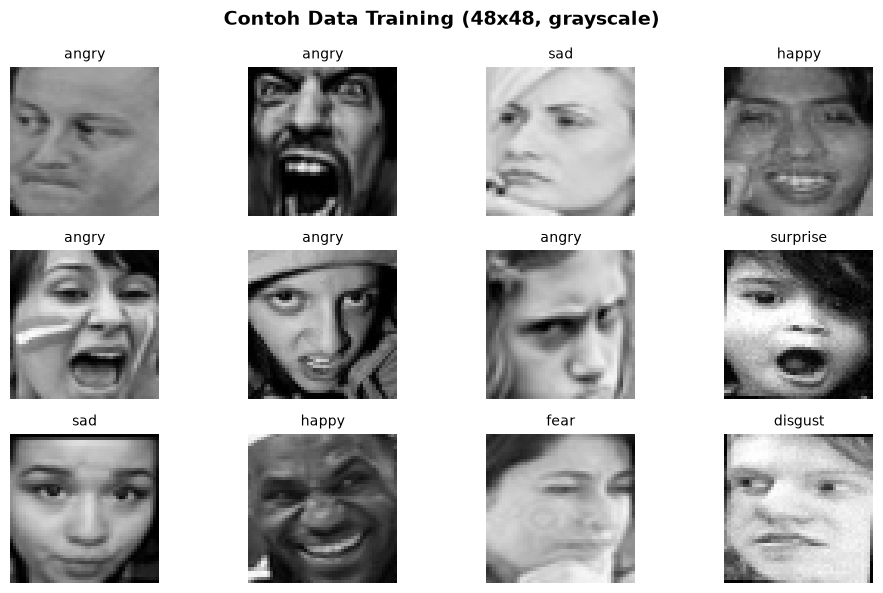

In [12]:
# Contoh data training setelah pra-pemrosesan (resize 48x48, grayscale)
plt.figure(figsize=(10, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(xb[i].numpy().squeeze().astype('uint8'), cmap='gray', vmin=0, vmax=255)
    plt.title(class_names[int(np.argmax(yb[i]))], fontsize=10)
    plt.axis('off')
plt.suptitle('Contoh Data Training (48x48, grayscale)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '4_sample_training.png'), dpi=120, bbox_inches='tight')
plt.show()

## Langkah 4 — Pembangunan Model CNN
Arsitektur: 3 blok konvolusi (Conv2D + ReLU + BatchNorm, MaxPooling, Dropout) → Flatten → Dense 256 (ReLU) → Dropout → Dense softmax.
Optimizer Adam, loss categorical crossentropy.

In [13]:
augment = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),     # shift
], name='augmentation')

inputs = layers.Input(shape=IMG_SIZE + (1,), name='input_image')
x = augment(inputs)
x = layers.Rescaling(1. / 255, name='normalisasi_0_1')(x)       # normalisasi piksel 0-1

# Blok 1
x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.25)(x)

# Blok 2
x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.25)(x)

# Blok 3
x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(128, (3, 3), padding='same', activation='relu', name='last_conv')(x)  # dipakai Grad-CAM
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.25)(x)

# Fully connected
x = layers.Flatten()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='output_softmax')(x)

model = models.Model(inputs, outputs, name='emotion_cnn')
model.compile(
    optimizer=Adam(LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)
model.summary()

Model: "emotion_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisasi_0_1 (Rescaling)     │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             

 Total params: 1,470,951 (5.61 MB)

 Trainable params: 1,469,543 (5.61 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [14]:
ckpt_path = os.path.join(OUT_DIR, 'emotion_cnn_best.keras')
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
    ModelCheckpoint(ckpt_path, monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-6),
]

t0 = time.time()
print('Mulai training CNN...')
h = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds, callbacks=callbacks)
train_minutes = (time.time() - t0) / 60
print(f'\nTotal waktu training: {train_minutes:.1f} menit')

history = {k: [float(v) for v in vals] for k, vals in h.history.items()}
best_epoch = int(np.argmax(history['val_accuracy'])) + 1
print(f'Epoch terbaik (val_accuracy tertinggi): {best_epoch}')

# Simpan model & riwayat training (dipakai dashboard Streamlit)
MODEL_PATH = os.path.join(OUT_DIR, 'emotion_cnn_model.keras')
model.save(MODEL_PATH)
with open(os.path.join(OUT_DIR, 'history.json'), 'w') as f:
    json.dump(history, f)

training_config = {
    'arsitektur': '3 blok Conv2D(32,64,128) x2 + BatchNorm + MaxPool + Dropout, Flatten, Dense 256 ReLU, Dropout 0.5, Dense softmax',
    'input_shape': list(IMG_SIZE) + [1],
    'optimizer': 'Adam',
    'learning_rate_awal': LEARNING_RATE,
    'loss': 'categorical_crossentropy',
    'batch_size': BATCH,
    'epoch_maksimum': EPOCHS,
    'epoch_dijalankan': len(history['loss']),
    'epoch_terbaik': best_epoch,
    'augmentasi': 'flip horizontal, rotasi 0.08, zoom 0.1, shift 0.1',
    'total_parameter': int(model.count_params()),
    'waktu_training_menit': round(train_minutes, 2),
}
with open(os.path.join(OUT_DIR, 'training_config.json'), 'w') as f:
    json.dump(training_config, f, indent=2)

loaded = tf.keras.models.load_model(MODEL_PATH, compile=False)
print(f"Model tersimpan di '{MODEL_PATH}' dan berhasil di-load ulang.")

Mulai training CNN...
Epoch 1/40


c:\Users\Axioo\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


623/623 ━━━━━━━━━━━━━━━━━━━━ 459s 708ms/step - accuracy: 0.2986 - loss: 1.9639 - val_accuracy: 0.3422 - val_loss: 1.7664 - learning_rate: 0.0010
Epoch 2/40
623/623 ━━━━━━━━━━━━━━━━━━━━ 362s 582ms/step - accuracy: 0.4332 - loss: 1.4979 - val_accuracy: 0.4677 - val_loss: 1.4023 - learning_rate: 0.0010
Epoch 3/40
623/623 ━━━━━━━━━━━━━━━━━━━━ 373s 599ms/step - accuracy: 0.4873 - loss: 1.3652 - val_accuracy: 0.4103 - val_loss: 1.6503 - learning_rate: 0.0010
Epoch 4/40
623/623 ━━━━━━━━━━━━━━━━━━━━ 378s 607ms/step - accuracy: 0.5207 - loss: 1.2846 - val_accuracy: 0.4227 - val_loss: 1.6729 - learning_rate: 0.0010
Epoch 5/40
623/623 ━━━━━━━━━━━━━━━━━━━━ 380s 610ms/step - accuracy: 0.5400 - loss: 1.2339 - val_accuracy: 0.5245 - val_loss: 1.2749 - learning_rate: 0.0010
Epoch 6/40
623/623 ━━━━━━━━━━━━━━━━━━━━ 365s 586ms/step - accuracy: 0.5488 - loss: 1.2137 - val_accuracy: 0.4942 - val_loss: 1.3559 - learning_rate: 0.0010
Epoch 7/40
623/623 ━━━━━━━━━━━━━━━━━━━━ 371s 595ms/step - accuracy: 0.5652 

## Langkah 5 — Evaluasi Model

In [15]:
# Evaluasi pada data uji (20%)
loss, acc = model.evaluate(val_ds, verbose=0)
print(f'Akurasi Validasi/Test: {acc * 100:.2f}%')
print(f'Loss Validasi/Test   : {loss:.4f}')

# Prediksi seluruh data uji (val_ds tidak di-shuffle, urutannya sama dengan y_val)
probs = model.predict(val_ds, verbose=0)
y_true = np.asarray(y_val, dtype=int)
y_pred = np.argmax(probs, axis=1)
assert len(y_true) == len(y_pred), 'Jumlah label dan prediksi tidak sama'
labels = list(range(NUM_CLASSES))

print('\nCLASSIFICATION REPORT\n')
print(classification_report(y_true, y_pred, labels=labels, target_names=class_names,
                            digits=3, zero_division=0))

report = classification_report(y_true, y_pred, labels=labels, target_names=class_names,
                               digits=3, zero_division=0, output_dict=True)

# Tabel ringkasan metrik
df_report = pd.DataFrame(report).T.loc[class_names + ['macro avg', 'weighted avg']]
df_report = df_report.rename(columns={'precision': 'Precision', 'recall': 'Recall',
                                      'f1-score': 'F1-Score', 'support': 'Jumlah data'})
df_report['Jumlah data'] = df_report['Jumlah data'].astype(int)
print('\nTABEL EVALUASI')
display(df_report.round(3))

accuracy = accuracy_score(y_true, y_pred)
print(f'\nAccuracy           : {accuracy:.4f}')
print(f"Precision (macro)  : {report['macro avg']['precision']:.4f}")
print(f"Recall    (macro)  : {report['macro avg']['recall']:.4f}")
print(f"F1-Score  (macro)  : {report['macro avg']['f1-score']:.4f}")
print(f"Precision (weighted): {report['weighted avg']['precision']:.4f}")
print(f"Recall    (weighted): {report['weighted avg']['recall']:.4f}")
print(f"F1-Score  (weighted): {report['weighted avg']['f1-score']:.4f}")

eval_metrics = {
    'accuracy': float(accuracy),
    'loss': float(loss),
    'class_names': class_names,
    'report': report,
}
with open(os.path.join(OUT_DIR, 'eval_metrics.json'), 'w') as f:
    json.dump(eval_metrics, f, indent=2)

Akurasi Validasi/Test: 61.36%
Loss Validasi/Test   : 1.0913

CLASSIFICATION REPORT

              precision    recall  f1-score   support

       angry      0.546     0.486     0.514      1184
     disgust      0.523     0.768     0.622      1184
        fear      0.429     0.453     0.440      1184
       happy      0.892     0.774     0.829      2280
     neutral      0.633     0.468     0.538      1633
         sad      0.514     0.464     0.488      1307
    surprise      0.615     0.806     0.698      1184

    accuracy                          0.614      9956
   macro avg      0.593     0.603     0.590      9956
weighted avg      0.627     0.614     0.613      9956


TABEL EVALUASI


,Precision,Recall,F1-Score,Jumlah data
angry,0.546,0.486,0.514,1184
disgust,0.523,0.768,0.622,1184
fear,0.429,0.453,0.440,1184
happy,0.892,0.774,0.829,2280
neutral,0.633,0.468,0.538,1633
sad,0.514,0.464,0.488,1307
surprise,0.615,0.806,0.698,1184
macro avg,0.593,0.603,0.590,9956
weighted avg,0.627,0.614,0.613,9956



Accuracy           : 0.6136
Precision (macro)  : 0.5932
Recall    (macro)  : 0.6025
F1-Score  (macro)  : 0.5899
Precision (weighted): 0.6270
Recall    (weighted): 0.6136
F1-Score  (weighted): 0.6126


In [16]:
# Interpretasi hasil (dihitung otomatis dari hasil di atas)
f1_per_class = {c: report[c]['f1-score'] for c in class_names}
best_c = max(f1_per_class, key=f1_per_class.get)
worst_c = min(f1_per_class, key=f1_per_class.get)
macro = report['macro avg']

print('INTERPRETASI HASIL')
print(f'- Akurasi {accuracy * 100:.2f}%: dari tiap 100 gambar uji, sekitar {accuracy * 100:.0f} dikenali dengan benar.')
print(f"- F1-score macro {macro['f1-score']:.3f} (precision {macro['precision']:.3f}, recall {macro['recall']:.3f}): "
      'F1 merupakan rata-rata harmonik precision dan recall, sehingga mencerminkan keseimbangan keduanya.')
print(f'- Kelas paling mudah dikenali : {best_c} (F1 = {f1_per_class[best_c]:.3f})')
print(f'- Kelas paling sulit dikenali : {worst_c} (F1 = {f1_per_class[worst_c]:.3f})')
print(f'- Kelas paling sedikit datanya ({min_c}) memiliki F1 = {f1_per_class[min_c]:.3f}, '
      f'sedangkan kelas terbanyak ({max_c}) F1 = {f1_per_class[max_c]:.3f}.')
print('\nPerbandingan F1-score antar kelas (terurut):')
for c, v in sorted(f1_per_class.items(), key=lambda kv: -kv[1]):
    print(f'   {c:<12s} {v:.3f}  (jumlah data uji: {int(report[c]["support"])})')

INTERPRETASI HASIL
- Akurasi 61.36%: dari tiap 100 gambar uji, sekitar 61 dikenali dengan benar.
- F1-score macro 0.590 (precision 0.593, recall 0.603): F1 merupakan rata-rata harmonik precision dan recall, sehingga mencerminkan keseimbangan keduanya.
- Kelas paling mudah dikenali : happy (F1 = 0.829)
- Kelas paling sulit dikenali : fear (F1 = 0.440)
- Kelas paling sedikit datanya (angry) memiliki F1 = 0.514, sedangkan kelas terbanyak (happy) F1 = 0.829.

Perbandingan F1-score antar kelas (terurut):
   happy        0.829  (jumlah data uji: 2280)
   surprise     0.698  (jumlah data uji: 1184)
   disgust      0.622  (jumlah data uji: 1184)
   neutral      0.538  (jumlah data uji: 1633)
   angry        0.514  (jumlah data uji: 1184)
   sad          0.488  (jumlah data uji: 1307)
   fear         0.440  (jumlah data uji: 1184)


## Langkah 6 — Visualisasi Hasil

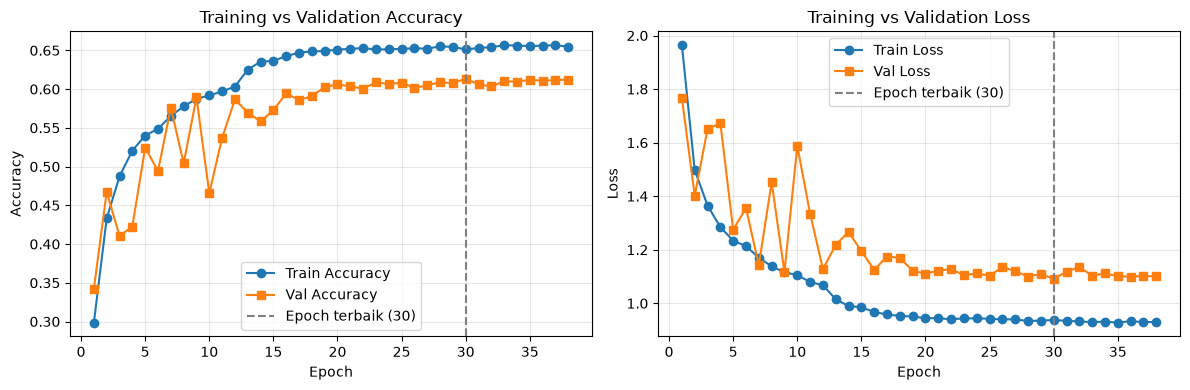

In [17]:
# 6a. Grafik akurasi dan loss selama training
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, len(history['loss']) + 1)
for a, (metric, title) in zip(ax, [('accuracy', 'Accuracy'), ('loss', 'Loss')]):
    a.plot(epochs_range, history[metric], 'o-', label=f'Train {title}')
    a.plot(epochs_range, history[f'val_{metric}'], 's-', label=f'Val {title}')
    a.axvline(best_epoch, color='gray', linestyle='--', label=f'Epoch terbaik ({best_epoch})')
    a.set_title(f'Training vs Validation {title}')
    a.set_xlabel('Epoch'); a.set_ylabel(title)
    a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '5_training_curves.png'), dpi=120, bbox_inches='tight')
plt.show()

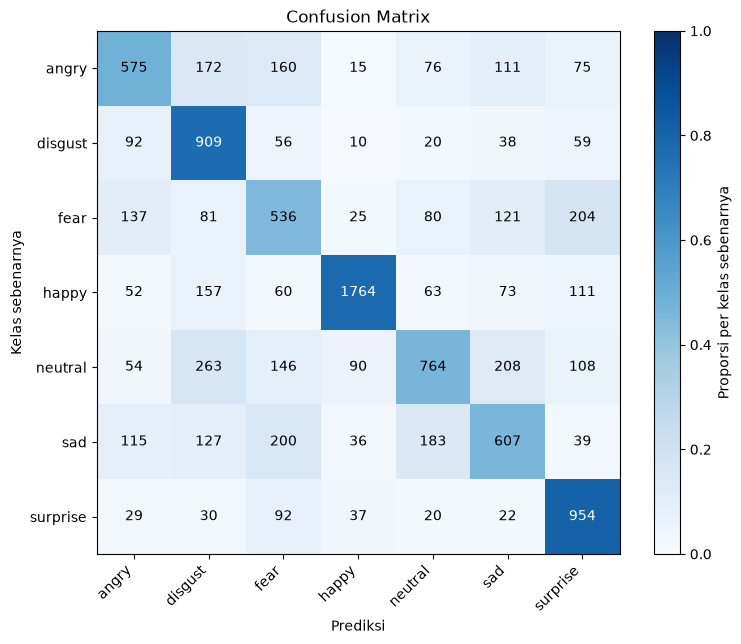

Kesalahan klasifikasi terbanyak (kelas asli -> diprediksi sebagai):
   neutral -> disgust: 263 gambar
   neutral -> sad: 208 gambar
   fear -> surprise: 204 gambar
   sad -> fear: 200 gambar
   sad -> neutral: 183 gambar


In [18]:
# 6b. Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=labels)
row_sum = cm.sum(axis=1, keepdims=True)
cm_pct = np.divide(cm, row_sum, out=np.zeros_like(cm, dtype=float), where=row_sum != 0)

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='Proporsi per kelas sebenarnya')
ax.set_xticks(labels); ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_yticks(labels); ax.set_yticklabels(class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                color='white' if cm_pct[i, j] > 0.5 else 'black')
ax.set_xlabel('Prediksi'); ax.set_ylabel('Kelas sebenarnya')
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '6_confusion_matrix.png'), dpi=120, bbox_inches='tight')
plt.show()

with open(os.path.join(OUT_DIR, 'confusion_matrix.json'), 'w') as f:
    json.dump({'class_names': class_names, 'matrix': cm.tolist()}, f)

# Pasangan kelas yang paling sering tertukar
pairs = [(int(cm[i, j]), i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
pairs.sort(reverse=True)
print('Kesalahan klasifikasi terbanyak (kelas asli -> diprediksi sebagai):')
for n, i, j in pairs[:5]:
    print(f'   {class_names[i]} -> {class_names[j]}: {n} gambar')

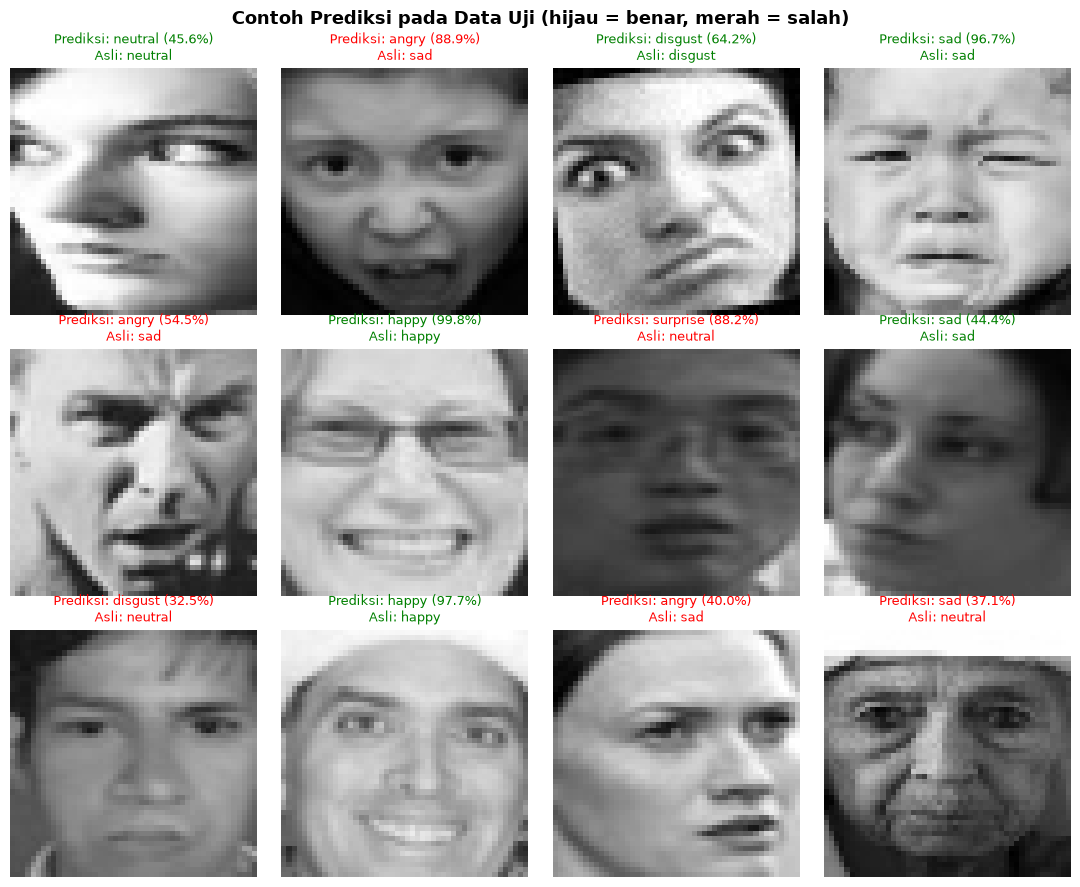

In [19]:
# 6c. Contoh hasil prediksi bersama label aslinya
x_val_all = np.concatenate([xb_.numpy() for xb_, _ in val_ds], axis=0)   # (N, 48, 48, 1), skala 0-255
assert len(x_val_all) == len(y_true)

rng = np.random.default_rng(SEED)
pick = rng.choice(len(x_val_all), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(11, 9))
for a, i in zip(axes.flatten(), pick):
    pred, true = int(y_pred[i]), int(y_true[i])
    conf = probs[i][pred] * 100
    a.imshow(x_val_all[i].squeeze(), cmap='gray', vmin=0, vmax=255)
    a.set_title(f'Prediksi: {class_names[pred]} ({conf:.1f}%)\nAsli: {class_names[true]}',
                color='green' if pred == true else 'red', fontsize=9)
    a.axis('off')
plt.suptitle('Contoh Prediksi pada Data Uji (hijau = benar, merah = salah)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '7_sample_predictions.png'), dpi=120, bbox_inches='tight')
plt.show()

c:\Users\Axioo\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\models\functional.py:293: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_image']
Received: inputs=Tensor(shape=(1, 48, 48, 1))
  warnings.warn(msg)


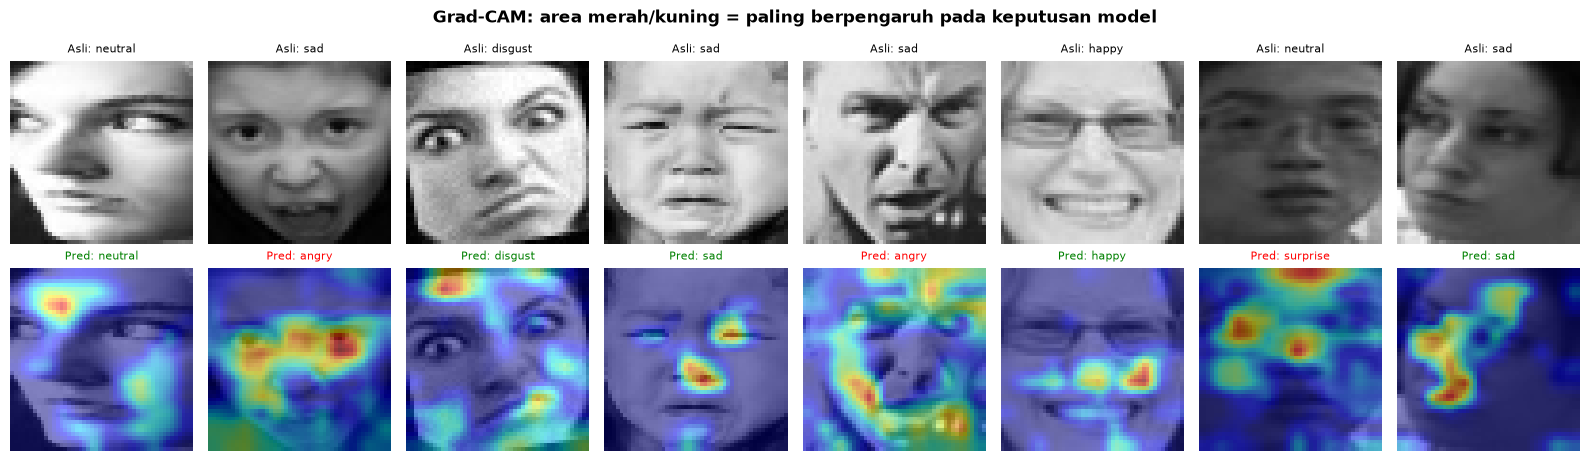

In [20]:
# 6d. Feature importance: Grad-CAM (area gambar yang paling memengaruhi keputusan model)
def make_gradcam(img_batch, model, last_conv_name='last_conv'):
    grad_model = tf.keras.models.Model(
        model.inputs, [model.get_layer(last_conv_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_batch, training=False)
        pred_index = tf.argmax(preds[0])
        class_score = preds[:, pred_index]
    grads = tape.gradient(class_score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))                       # bobot tiap channel
    cam = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], IMG_SIZE).numpy().squeeze()   # kembali ke 48x48
    return cam, int(pred_index)

n_cam = 8
cam_idx = pick[:n_cam]
fig, axes = plt.subplots(2, n_cam, figsize=(n_cam * 2, 4.8))
for k, i in enumerate(cam_idx):
    img = x_val_all[i]
    cam, pred = make_gradcam(img[None, ...], model)
    true = int(y_true[i])
    axes[0, k].imshow(img.squeeze(), cmap='gray', vmin=0, vmax=255)
    axes[0, k].set_title(f'Asli: {class_names[true]}', fontsize=8)
    axes[0, k].axis('off')
    axes[1, k].imshow(img.squeeze(), cmap='gray', vmin=0, vmax=255)
    axes[1, k].imshow(cam, cmap='jet', alpha=0.5, vmin=0, vmax=1)
    axes[1, k].set_title(f'Pred: {class_names[pred]}', fontsize=8,
                         color='green' if pred == true else 'red')
    axes[1, k].axis('off')
plt.suptitle('Grad-CAM: area merah/kuning = paling berpengaruh pada keputusan model',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '8_gradcam.png'), dpi=120, bbox_inches='tight')
plt.show()

## Selesai
Semua artefak tersimpan di folder `output/`. Jalankan dashboard (Langkah 7) dari terminal, di folder yang berisi `app.py` dan folder `output/`:

```
streamlit run app.py
```

In [21]:
print('Hasil disimpan di:', os.path.abspath(OUT_DIR))
for fn in sorted(os.listdir(OUT_DIR)):
    print('-', fn)

Hasil disimpan di: d:\emosiiii\output
- 1_class_distribution.png
- 2_sample_per_class.png
- 3_image_quality.png
- 4_sample_training.png
- 5_training_curves.png
- 6_confusion_matrix.png
- 7_sample_predictions.png
- 8_gradcam.png
- class_names.json
- confusion_matrix.json
- dataset_summary.json
- emotion_cnn_best.keras
- emotion_cnn_model.keras
- eval_metrics.json
- history.json
- training_config.json
